# Deep Learning, Phase 3 (Sequential Models), Day 2: RNNs in PyTorch and the Vanishing Gradient


In [ ]:
import copy, time, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
sns.set_theme(style='whitegrid')
np.random.seed(42); torch.manual_seed(0)

## 1. The same data and split as Day 1

In [ ]:
n = 1200; t = np.arange(n)
series = np.sin(0.05 * t) + 0.3 * np.sin(0.013 * t) + 0.1 * np.random.randn(n)       # same series as Day 1 (same seed)
n_tr, n_va = int(0.70 * n), int(0.15 * n)
s_train, s_val, s_test = series[:n_tr], series[n_tr:n_tr + n_va], series[n_tr + n_va:]          # chronological split
scaler = StandardScaler().fit(s_train.reshape(-1, 1))                                          # statistics from the training part only
tr, va, te = (scaler.transform(s.reshape(-1, 1)).ravel() for s in (s_train, s_val, s_test))

def make_windows(x, k):
    return np.array([x[i:i + k] for i in range(len(x) - k)]), x[k:]
K = 20
Xtr, ytr = make_windows(tr, K); Xva, yva = make_windows(va, K); Xte, yte = make_windows(te, K)        # test windows stay locked
print('Windows  train', Xtr.shape, '| validation', Xva.shape, '| test (locked)', Xte.shape)

def scores(y_true, y_pred): return {'MAE': mean_absolute_error(y_true, y_pred), 'RMSE': np.sqrt(mean_squared_error(y_true, y_pred))}
pred_naive = Xva[:, -1]; pred_lin = LinearRegression().fit(Xtr, ytr).predict(Xva)
baselines = pd.DataFrame({'Naive (last value)': scores(yva, pred_naive), 'Linear regression': scores(yva, pred_lin)}).T
baselines.round(4)

Windows  train (820, 20) | validation (160, 20) | test (locked) (160, 20)


,MAE,RMSE
Naive (last value),0.1548,0.1894
Linear regression,0.1156,0.1440


## 2. `nn.RNN`: the shapes you must know
`nn.RNN(input_size, hidden_size, num_layers=1, batch_first=True)` expects the input as **(batch, time, features)**. It returns two things:
- `output`: the hidden state at **every** time step, shape (batch, time, hidden)
- `h_n`: the hidden state at the **last** step of each layer, shape (num_layers, batch, hidden)

For a many-to-one task we use the **last** hidden state.

In [ ]:
rnn = nn.RNN(input_size=1, hidden_size=8, batch_first=True)
x = torch.randn(4, 20, 1)                       # 4 sequences, 20 time steps, 1 feature each
output, h_n = rnn(x)
print('input  :', tuple(x.shape), '(batch, time, features)')
print('output :', tuple(output.shape), '(batch, time, hidden)  <- hidden state at every step')
print('h_n    :', tuple(h_n.shape), '(layers, batch, hidden)  <- hidden state of the last step')
print('Last output equals h_n?', torch.allclose(output[:, -1], h_n[0]))
print('Parameters:', {k: tuple(v.shape) for k, v in rnn.named_parameters()}, '| total', sum(p.numel() for p in rnn.parameters()))

input  : (4, 20, 1) (batch, time, features)
output : (4, 20, 8) (batch, time, hidden)  <- hidden state at every step
h_n    : (1, 4, 8) (layers, batch, hidden)  <- hidden state of the last step
Last output equals h_n? True
Parameters: {'weight_ih_l0': (8, 1), 'weight_hh_l0': (8, 8), 'bias_ih_l0': (8,), 'bias_hh_l0': (8,)} | total 88


The four parameter tensors are exactly the ones we wrote by hand yesterday: `weight_ih` is `W_x`, `weight_hh` is `W_h`, and there are two biases (PyTorch uses `b_ih + b_hh`).

## 3. An RNN forecaster
Input: a window of `K = 20` past values. The RNN reads them step by step, and a linear layer turns the **last hidden state** into the prediction of the next value.

In [ ]:
class RNNForecaster(nn.Module):
    def __init__(self, hidden=32, layers=1, kind='rnn'):
        super().__init__()
        cell = {'rnn': nn.RNN, 'lstm': nn.LSTM, 'gru': nn.GRU}[kind]          # we will reuse this class on Day 3
        self.rnn = cell(1, hidden, num_layers=layers, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):                           # x: (batch, time, 1)
        out, _ = self.rnn(x)
        return self.fc(out[:, -1]).squeeze(1)       # last time step -> one number per sequence

to_t = lambda a: torch.tensor(a, dtype=torch.float32)
Xtr_t, ytr_t, Xva_t, yva_t = to_t(Xtr)[..., None], to_t(ytr), to_t(Xva)[..., None], to_t(yva)       # add the features axis
model = RNNForecaster()
print(model); print('Parameters:', sum(p.numel() for p in model.parameters()))

RNNForecaster(
  (rnn): RNN(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)
Parameters: 1153


## 4. Training
- Loss: **MSE** (regression). Optimizer: Adam.
- **Gradient clipping** (`clip_grad_norm_`): if the gradient is larger than a limit, it is scaled down. This protects against **exploding gradients** (see section 5).
- Keep the best epoch by validation loss.

Trained in 17.6s | best epoch 29 | best validation MSE 0.0229


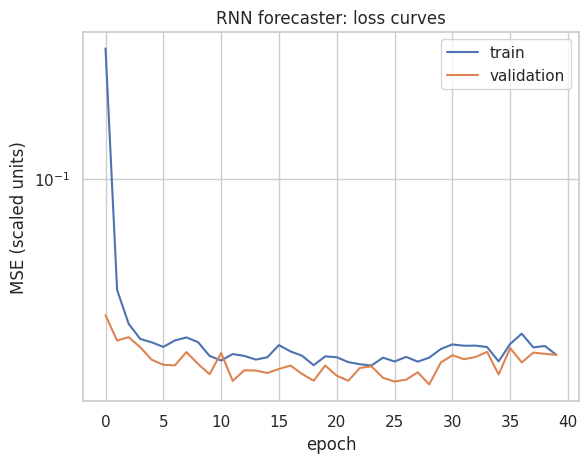

In [ ]:
def train(model, Xtr, ytr, Xva, yva, epochs=40, lr=5e-3, batch=64, clip=1.0, seed=0):
    torch.manual_seed(seed); opt = torch.optim.Adam(model.parameters(), lr=lr); loss_fn = nn.MSELoss()
    hist = {'loss': [], 'val_loss': []}; best, best_state, best_ep = float('inf'), None, 0
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr)); run = 0
        for i in range(0, len(Xtr), batch):
            idx = perm[i:i + batch]; opt.zero_grad(); loss = loss_fn(model(Xtr[idx]), ytr[idx]); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), clip); opt.step(); run += loss.item() * len(idx)
        model.eval()
        with torch.no_grad(): vl = loss_fn(model(Xva), yva).item()
        hist['loss'].append(run / len(Xtr)); hist['val_loss'].append(vl)
        if vl < best: best, best_state, best_ep = vl, copy.deepcopy(model.state_dict()), ep + 1
    model.load_state_dict(best_state); hist['best_epoch'] = best_ep; return hist

t0 = time.time(); h = train(model, Xtr_t, ytr_t, Xva_t, yva_t)
print(f'Trained in {time.time() - t0:.1f}s | best epoch {h["best_epoch"]} | best validation MSE {min(h["val_loss"]):.4f}')
plt.plot(h['loss'], label='train'); plt.plot(h['val_loss'], label='validation'); plt.xlabel('epoch'); plt.ylabel('MSE (scaled units)'); plt.yscale('log'); plt.legend(); plt.title('RNN forecaster: loss curves'); plt.show()

## 5. Compare with the baselines (validation set)

,MAE,RMSE
Naive (last value),0.1548,0.1894
Linear regression,0.1156,0.1440
"RNN (1 layer, 32 units)",0.1229,0.1514


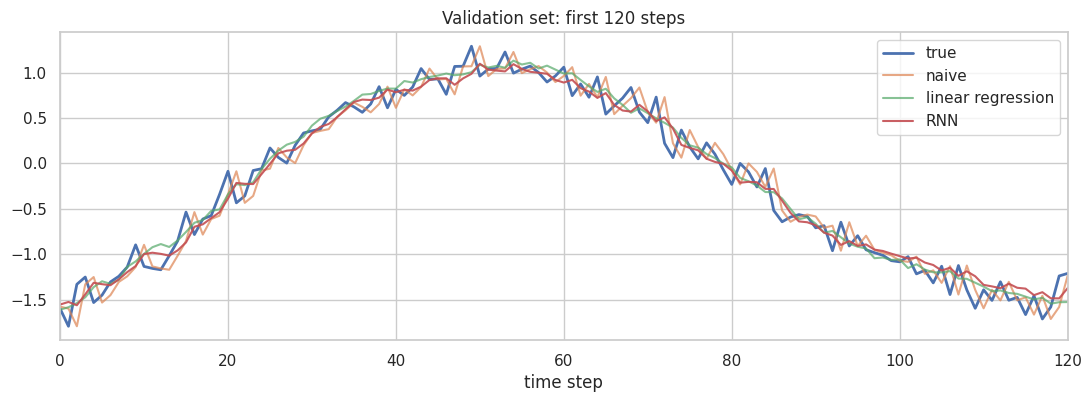

In [ ]:
model.eval()
with torch.no_grad(): pred_rnn = model(Xva_t).numpy()
cmp = pd.concat([baselines, pd.DataFrame({'RNN (1 layer, 32 units)': scores(yva, pred_rnn)}).T]).round(4); display(cmp)

plt.figure(figsize=(13, 4)); plt.plot(yva, label='true', lw=2); plt.plot(pred_naive, label='naive', alpha=.7); plt.plot(pred_lin, label='linear regression', alpha=.7); plt.plot(pred_rnn, label='RNN', alpha=.9)
plt.xlim(0, 120); plt.xlabel('time step'); plt.legend(); plt.title('Validation set: first 120 steps'); plt.show()

## 6. Measuring the vanishing gradient
Training adjusts the weights with gradients. The gradient of the final hidden state with respect to the input at an **earlier time step** tells us how much that old input can influence the result (and therefore how much the network can *learn* from it). Backpropagation through time multiplies by the recurrent weights and the `tanh` derivative at **every** step, so over many steps the gradient is multiplied by many numbers smaller than 1 and **vanishes** (or by numbers larger than 1 and **explodes**).

We measure it directly with autograd, for a random sequence of length 100:

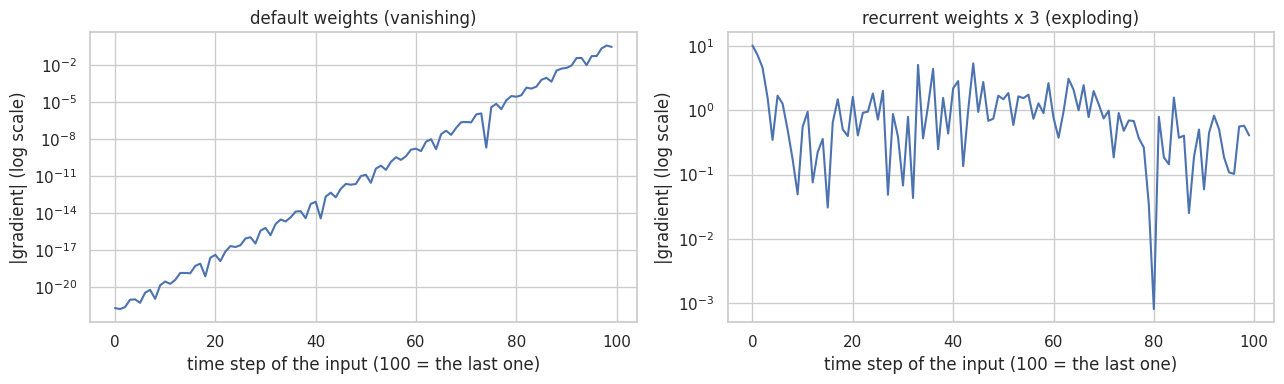

Default weights: gradient at the last step 2.81e-01, 10 steps back 5.56e-03, 50 steps back 1.22e-11, at the very first step 1.90e-22
Weights x 3    : gradient at the last step 4.05e-01, 10 steps back 5.88e-02, 50 steps back 1.48e+00, at the very first step 1.01e+01


In [ ]:
def gradient_profile(w_hh_scale=1.0, T=100, hidden=32, seed=0):
    torch.manual_seed(seed); rnn = nn.RNN(1, hidden, batch_first=True)
    with torch.no_grad(): rnn.weight_hh_l0.mul_(w_hh_scale)                  # scale the recurrent weights
    x = torch.randn(1, T, 1, requires_grad=True)
    _, h_n = rnn(x); h_n.sum().backward()                                   # gradient of the last hidden state w.r.t. every input
    return x.grad.abs().squeeze().numpy()

fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
for scale, label in [(1.0, 'default weights (vanishing)'), (3.0, 'recurrent weights x 3 (exploding)')]:
    g = gradient_profile(scale); ax[0 if scale == 1.0 else 1].semilogy(np.arange(len(g)), g); ax[0 if scale == 1.0 else 1].set(title=label, xlabel='time step of the input (100 = the last one)', ylabel='|gradient| (log scale)')
plt.tight_layout(); plt.show()
g = gradient_profile(1.0); print('Default weights: gradient at the last step %.2e, 10 steps back %.2e, 50 steps back %.2e, at the very first step %.2e' % (g[-1], g[-10], g[-50], g[0]))
g3 = gradient_profile(3.0); print('Weights x 3    : gradient at the last step %.2e, 10 steps back %.2e, 50 steps back %.2e, at the very first step %.2e' % (g3[-1], g3[-10], g3[-50], g3[0]))


## 7. A task where the RNN fails: remember the first element
Sequence of random numbers. The label is **whether the first number was positive**. Everything after the first number is noise, so the network must keep the first value in memory until the end. We train a plain RNN on sequences of length 5, 20, 50 and 100 (same model, same settings):

Sequence length   5: final validation accuracy 0.994
Sequence length  20: final validation accuracy 0.940
Sequence length  50: final validation accuracy 0.530
Sequence length 100: final validation accuracy 0.962


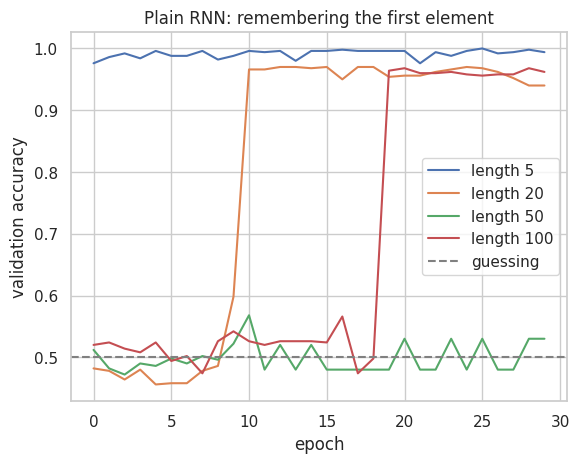

In [ ]:
def memory_data(n, T, seed):
    g = torch.Generator().manual_seed(seed); x = torch.randn(n, T, 1, generator=g); return x, (x[:, 0, 0] > 0).float()

class MemoryNet(nn.Module):
    def __init__(self, hidden=32, kind='rnn'):
        super().__init__(); self.rnn = {'rnn': nn.RNN, 'lstm': nn.LSTM, 'gru': nn.GRU}[kind](1, hidden, batch_first=True); self.fc = nn.Linear(hidden, 1)
    def forward(self, x): o, _ = self.rnn(x); return self.fc(o[:, -1]).squeeze(1)

def run_memory_task(T, kind='rnn', epochs=30, seed=0):
    torch.manual_seed(seed); xtr, ytr = memory_data(2000, T, 1); xva, yva = memory_data(500, T, 2)
    m = MemoryNet(kind=kind); opt = torch.optim.Adam(m.parameters(), lr=0.01); lf = nn.BCEWithLogitsLoss(); accs = []
    for ep in range(epochs):
        m.train(); perm = torch.randperm(2000)
        for i in range(0, 2000, 64):
            idx = perm[i:i + 64]; opt.zero_grad(); lf(m(xtr[idx]), ytr[idx]).backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
        m.eval()
        with torch.no_grad(): accs.append(((m(xva) > 0).float() == yva).float().mean().item())
    return accs

lengths = [5, 20, 50, 100]; curves = {T: run_memory_task(T) for T in lengths}
for T in lengths: print(f'Sequence length {T:3d}: final validation accuracy {curves[T][-1]:.3f}')
for T in lengths: plt.plot(curves[T], label=f'length {T}')
plt.axhline(0.5, color='grey', ls='--', label='guessing'); plt.xlabel('epoch'); plt.ylabel('validation accuracy'); plt.title('Plain RNN: remembering the first element'); plt.legend(); plt.show()